# Five-epoch model: assessment

The YOLOv8m-seg trial model (`runs/synth_eval/trial5`): COCO-pretrained, fine-tuned for **5 epochs**
on the 100-frame `synth` set with the `configs/train.toml` augmentation. Inference only here; no
training.

- **Quantitative:** tile-level mask mAP, frame-level detection and geometry in robot units (mm,
  degrees) against the `docs/plan.md` targets, error distributions, breakdowns by body type and by
  position relative to tile seams, confidence behaviour, timing.
- **Qualitative:** full frames, a random gallery, the worst bodies by each measure, close-ups of the
  outline, bodies on tile seams, and what the model nearly detects.

**Data caveat.** `synth_val` and `synth_test` (20 frames each) are unseen frames from the *same
generator* as the training set. Everything here is an upper bound for real frames; it shows the
pipeline and the model's geometric precision, not real-world robustness.

Colour key in every image: **labels green, predictions magenta**.

In [1]:
import json
import os

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from shapely.geometry import Polygon
from ultralytics import YOLO

from robot_offline import config, evaluate, manifest, tiling

ROOT = config.ROOT
os.chdir(ROOT)
pd.set_option("display.precision", 3)

RUN = ROOT / "runs" / "synth_eval" / "trial5"
WEIGHTS = RUN / "weights" / "best.pt"
DS = config.load("dataset")
PX_PER_MM = DS["scale"]["px_per_mm"]
AREA = DS["work_area"]
WORK_AREA = (AREA["x0"], AREA["y0"], AREA["width"], AREA["height"])
TILE, OVERLAP = DS["tiles"]["size"], DS["tiles"]["overlap"]
CONF = 0.25          # operating threshold (ultralytics default)
SWEEP_FLOOR = 0.05   # predictions are collected down to here so thresholds can be swept offline

# Chart colours: categorical slots 1 and 2 (blue, orange); targets in neutral ink.
C1, C2, INK, MUTED = "#2a78d6", "#eb6834", "#2b2b2b", "#8a8a85"
GT_BGR, PRED_BGR = (0, 200, 0), (255, 0, 255)
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e6e3", "grid.linewidth": 0.6,
    "axes.edgecolor": MUTED, "axes.titlesize": 11, "axes.labelsize": 10, "lines.linewidth": 2,
})

model = YOLO(str(WEIGHTS))
labels = manifest.load(DS["labels"]["rules_version"])
SETS = {name: [s for s in labels["samples"] if s["session"] == name]
        for name in ("synth_val", "synth_test")}
TILES = tiling.tiles(WORK_AREA, (4608, 2592), TILE, OVERLAP)
_images = {}

def image(sample):
    if sample["image"] not in _images:
        _images[sample["image"]] = cv2.imread(str(config.DATA_DIR / sample["image"]))
    return _images[sample["image"]]

print(f"weights: {WEIGHTS.relative_to(ROOT)}  ({WEIGHTS.stat().st_size / 1e6:.0f} MB)")
print({k: len(v) for k, v in SETS.items()}, "frames;", len(TILES), "tiles per frame")

weights: runs\synth_eval\trial5\weights\best.pt  (55 MB)
{'synth_val': 20, 'synth_test': 20} frames; 8 tiles per frame


## 1. How it was trained

In [2]:
handoff = json.loads((RUN / "handoff.json").read_text())
args = handoff["train_args"]
keys = ["epochs", "batch", "imgsz", "degrees", "fliplr", "flipud", "scale", "hsv_h", "hsv_s",
        "hsv_v", "mosaic"]
pd.Series({k: args.get(k) for k in keys}, name="value").to_frame().T

,epochs,batch,imgsz,degrees,fliplr,flipud,scale,hsv_h,hsv_s,hsv_v,mosaic
value,5.0,4.0,1024.0,180.0,0.5,0.5,0.1,0.01,0.3,0.3,1.0


,metrics/precision(M),metrics/recall(M),metrics/mAP50(M),metrics/mAP50-95(M)
epoch,,,,
1,0.984,1.000,0.992,0.906
2,0.961,0.977,0.989,0.898
3,0.988,0.995,0.994,0.907
4,0.128,0.993,0.128,0.117
5,0.988,0.998,0.995,0.910


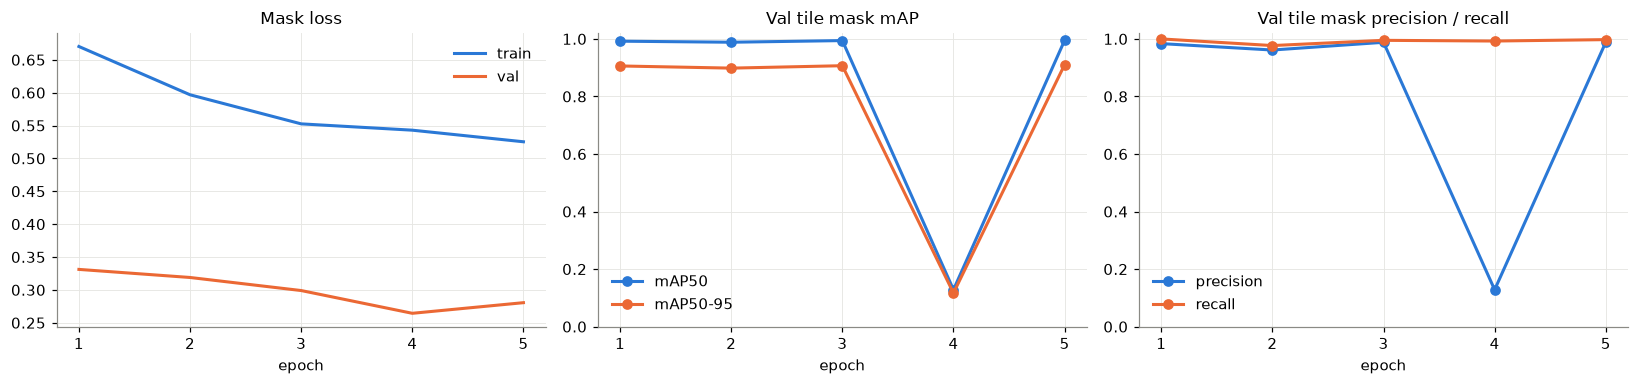

In [3]:
log = pd.read_csv(RUN / "results.csv")
log.columns = log.columns.str.strip()
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
ax = axes[0]
ax.plot(log["epoch"], log["train/seg_loss"], color=C1, label="train")
ax.plot(log["epoch"], log["val/seg_loss"], color=C2, label="val")
ax.set_title("Mask loss"); ax.set_xlabel("epoch"); ax.legend(frameon=False)
ax = axes[1]
ax.plot(log["epoch"], log["metrics/mAP50(M)"], color=C1, marker="o", label="mAP50")
ax.plot(log["epoch"], log["metrics/mAP50-95(M)"], color=C2, marker="o", label="mAP50-95")
ax.set_ylim(0, 1.02); ax.set_title("Val tile mask mAP"); ax.set_xlabel("epoch"); ax.legend(frameon=False)
ax = axes[2]
ax.plot(log["epoch"], log["metrics/precision(M)"], color=C1, marker="o", label="precision")
ax.plot(log["epoch"], log["metrics/recall(M)"], color=C2, marker="o", label="recall")
ax.set_ylim(0, 1.02); ax.set_title("Val tile mask precision / recall"); ax.set_xlabel("epoch")
ax.legend(frameon=False)
for ax in axes:
    ax.set_xticks(log["epoch"])
plt.tight_layout()
log[["epoch", "metrics/precision(M)", "metrics/recall(M)", "metrics/mAP50(M)",
     "metrics/mAP50-95(M)"]].set_index("epoch")

`best.pt` is the epoch with the best val fitness (ultralytics weights mAP50-95 most), so the
epoch-4 collapse in precision (the first epoch after the 3-epoch learning-rate warmup) does not
reach the saved model. It is still a sign that a longer run needs watching.

## 2. Tile-level metrics

Ultralytics' own validation on the 160 test tiles (1024 px), the same measure the fibre project
reported as `AP_mask`.

In [4]:
m = model.val(data=str(config.DATA_DIR / "yolo" / "synth_eval" / "dataset.yaml"), split="test",
              imgsz=TILE, batch=4, workers=2, plots=False, verbose=False)
pd.DataFrame({
    "mask": {"precision": m.seg.mp, "recall": m.seg.mr, "mAP50": m.seg.map50, "mAP75": m.seg.map75,
             "mAP50-95": m.seg.map},
    "box": {"precision": m.box.mp, "recall": m.box.mr, "mAP50": m.box.map50, "mAP75": m.box.map75,
            "mAP50-95": m.box.map},
}).T

Ultralytics 8.4.173  Python-3.11.9 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 3060 Laptop GPU, 6144MiB)


YOLOv8m-seg summary (fused): 105 layers, 27,222,963 parameters, 0 gradients, 104.3 GFLOPs


val: Fast image access  (ping: 0.10.0 ms, read: 2402.7639.0 MB/s, size: 372.3 KB)


val: Scanning C:\Users\joshp\Y4S1\Robot Resources\robot_offline\data\yolo\synth_eval\labels\test.cache... 160 images, 19 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 160/160  0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 2% ──────────── 1/40 15.5s/it 4.7s<10:05

...

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 97% ━━━━━━━━━━━╸ 39/40 5.0it/s 12.2s<0.2s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 40/40 3.2it/s 12.4s

                   all        160        421      0.993      0.999      0.995      0.961      0.993      0.999      0.995      0.902


Speed: 2.2ms preprocess, 43.7ms inference, 0.0ms loss, 1.5ms postprocess per image


,precision,recall,mAP50,mAP75,mAP50-95
mask,0.993,0.999,0.995,0.995,0.902
box,0.993,0.999,0.995,0.995,0.961


## 3. Full frames, in robot units

Each 4608 × 2592 frame is cut into 8 tiles, predicted, and merged with `robot_offline.tiling`, exactly
as the robot will run it. Predictions are matched one-to-one to labels at IoU ≥ 0.5. Geometry comes
from each polygon's minimum-area rectangle: centre, long side (length), short side (width), and yaw.

In [5]:
raw = {name: evaluate.evaluate_samples(model, frames, conf=SWEEP_FLOOR)
       for name, frames in SETS.items()}

def at_conf(results, frames, conf):
    # Re-scores stored predictions at a higher threshold (equivalent to predicting at it: the
    # merge keeps the higher-scoring of any duplicate pair).
    out = []
    for r, s in zip(results, frames):
        keep = [i for i, sc in enumerate(r["scores"]) if sc >= conf]
        polys = [r["polygons"][i] for i in keep]
        res = evaluate.score_frame(manifest.polygons(s), polys, PX_PER_MM)
        res.update(image=r["image"], seconds=r["seconds"], polygons=polys,
                   scores=[r["scores"][i] for i in keep])
        out.append(res)
    return out

res = {name: at_conf(raw[name], SETS[name], CONF) for name in SETS}
summary = pd.DataFrame({name: evaluate.summarise(r) for name, r in res.items()})
targets = pd.Series({"centre_mm_p95": "< 1.0", "yaw_deg_p95": "< 3.0",
                     "on_target_fraction": "≥ 0.95", "merges": "0", "false_det_on_empty": "0"})
summary["plan target"] = targets
summary["plan target"] = summary["plan target"].fillna("")
summary

,synth_val,synth_test,plan target
frames,20,20,
bodies,317,317,
precision,1.0,1.0,
recall,1.0,1.0,
f1,1.0,1.0,
misses,0,0,
false_detections,0,0,
false_det_on_empty,0,0,0
merges,0,0,0
splits,0,0,


`on_target_fraction` is over *all labelled bodies* (a miss counts as off target): the share whose
centre error is under 1 mm **and** yaw error under 3°.

In [6]:
def body_frame(results, frames):
    rows = []
    for r, s in zip(results, frames):
        for m in r["matched"]:
            rows.append({**m, "image": s["image"], "score": r["scores"][m["prediction_index"]]})
    df = pd.DataFrame(rows)
    df["package"] = np.where(df["true_length_mm"] < 7.5, "1/4 W", "1/2 W")
    return df

bodies = {name: body_frame(res[name], SETS[name]) for name in SETS}
test = bodies["synth_test"]
print(f"{len(test)} matched test bodies")

317 matched test bodies


### Error distributions (test)

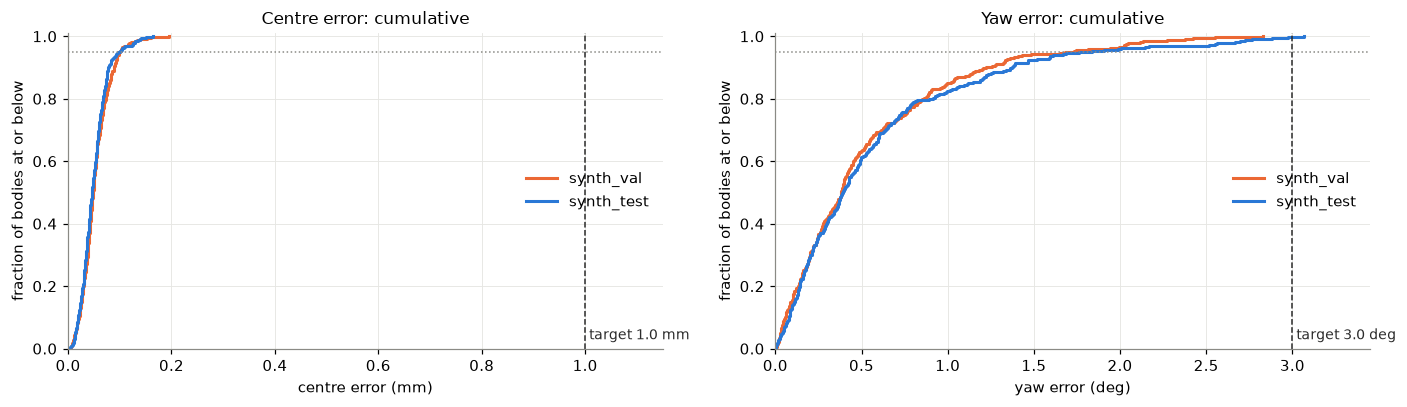

In [7]:
def ecdf(ax, values, colour, label):
    v = np.sort(values)
    ax.step(v, np.arange(1, len(v) + 1) / len(v), where="post", color=colour, label=label)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, col, target, unit in [(axes[0], "centre_mm", evaluate.CENTRE_TARGET_MM, "mm"),
                              (axes[1], "yaw_deg", evaluate.YAW_TARGET_DEG, "deg")]:
    for name, colour in [("synth_val", C2), ("synth_test", C1)]:
        ecdf(ax, bodies[name][col], colour, name)
    ax.axvline(target, color=INK, ls="--", lw=1)
    ax.axhline(0.95, color=MUTED, ls=":", lw=1)
    ax.text(target, 0.03, f" target {target} {unit}", color=INK, fontsize=9)
    ax.set_xlim(0, target * 1.15)
    ax.set_ylim(0, 1.01)
    ax.set_xlabel(f"{col.split('_')[0]} error ({unit})")
    ax.set_ylabel("fraction of bodies at or below")
    ax.legend(frameon=False, loc="center right")
axes[0].set_title("Centre error: cumulative"); axes[1].set_title("Yaw error: cumulative")
plt.tight_layout()

mean centre offset: dx = +0.012 mm, dy = -0.023 mm
p95 |length error| = 0.213 mm, p95 |width error| = 0.227 mm


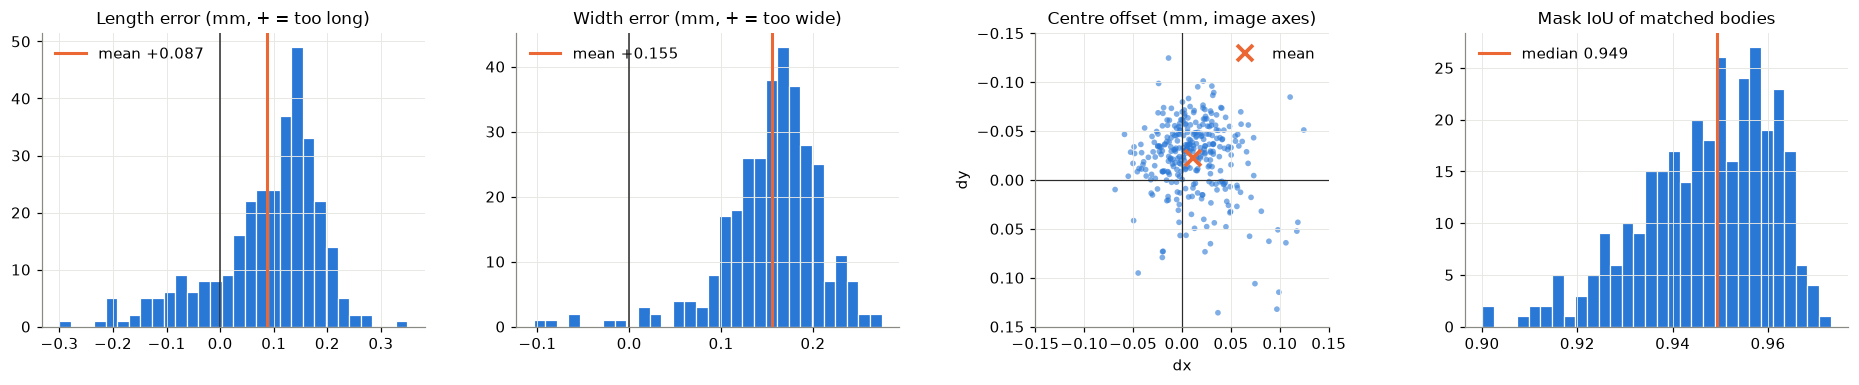

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
for ax, col, title in [(axes[0], "length_mm", "Length error (mm, + = too long)"),
                       (axes[1], "width_mm", "Width error (mm, + = too wide)")]:
    ax.hist(test[col], bins=30, color=C1, edgecolor="white", linewidth=0.8)
    ax.axvline(0, color=INK, lw=1)
    ax.axvline(test[col].mean(), color=C2, lw=2, label=f"mean {test[col].mean():+.3f}")
    ax.set_title(title); ax.legend(frameon=False)
ax = axes[2]
ax.scatter(test["dx_mm"], test["dy_mm"], s=14, color=C1, alpha=0.6, edgecolor="none")
ax.axhline(0, color=INK, lw=0.8); ax.axvline(0, color=INK, lw=0.8)
ax.plot(test["dx_mm"].mean(), test["dy_mm"].mean(), "x", color=C2, ms=10, mew=2.5, label="mean")
lim = max(0.15, np.abs(test[["dx_mm", "dy_mm"]].to_numpy()).max() * 1.1)
ax.set_xlim(-lim, lim); ax.set_ylim(lim, -lim); ax.set_aspect("equal")
ax.set_title("Centre offset (mm, image axes)"); ax.set_xlabel("dx"); ax.set_ylabel("dy")
ax.legend(frameon=False)
ax = axes[3]
ax.hist(test["iou"], bins=30, color=C1, edgecolor="white", linewidth=0.8)
ax.axvline(test["iou"].median(), color=C2, lw=2, label=f"median {test['iou'].median():.3f}")
ax.set_title("Mask IoU of matched bodies"); ax.legend(frameon=False)
plt.tight_layout()
print("mean centre offset: dx = %+.3f mm, dy = %+.3f mm" % (test["dx_mm"].mean(), test["dy_mm"].mean()))
print("p95 |length error| = %.3f mm, p95 |width error| = %.3f mm"
      % (test["length_mm"].abs().quantile(0.95), test["width_mm"].abs().quantile(0.95)))

### By body type

Package size from the label's length (¼ W about 6 mm, ½ W about 9 mm); film type from the body
colour inside the label (metal film is blue, carbon film beige).

In [9]:
def film(sample, polygon):
    mask = np.zeros(image(sample).shape[:2], np.uint8)
    cv2.fillPoly(mask, [np.round(polygon).astype(np.int32)], 1)
    b, g, r = cv2.mean(image(sample), mask)[:3]
    return "metal (blue)" if b > r else "carbon (beige)"

samples_by_image = {s["image"]: s for s in SETS["synth_test"]}
test["film"] = [film(samples_by_image[row.image],
                     manifest.polygons(samples_by_image[row.image])[row.label_index])
                for row in test.itertuples()]
cols = ["iou", "centre_mm", "yaw_deg", "length_mm", "width_mm"]
g = test.groupby(["package", "film"])
pd.concat([g.size().rename("bodies"), g[cols].mean().add_suffix(" mean"),
           g[["centre_mm", "yaw_deg"]].quantile(0.95).add_suffix(" p95")], axis=1)

bodies  iou mean  centre_mm mean  yaw_deg mean  \
package film                                                             
1/2 W   carbon (beige)      71     0.956           0.050         0.470   
        metal (blue)        80     0.959           0.047         0.374   
1/4 W   carbon (beige)      90     0.935           0.050         0.734   
        metal (blue)        76     0.940           0.052         0.713   

                        length_mm mean  width_mm mean  centre_mm p95  \
package film                                                           
1/2 W   carbon (beige)           0.077          0.166          0.102   
        metal (blue)             0.072          0.159          0.090   
1/4 W   carbon (beige)           0.102          0.148          0.093   
        metal (blue)             0.094          0.150          0.097   

                        yaw_deg p95  
package film                         
1/2 W   carbon (beige)        1.395  
        metal (blue)          1.011  
1/4 W   carbon (beige)        2.261  
        metal (blue)          2.551

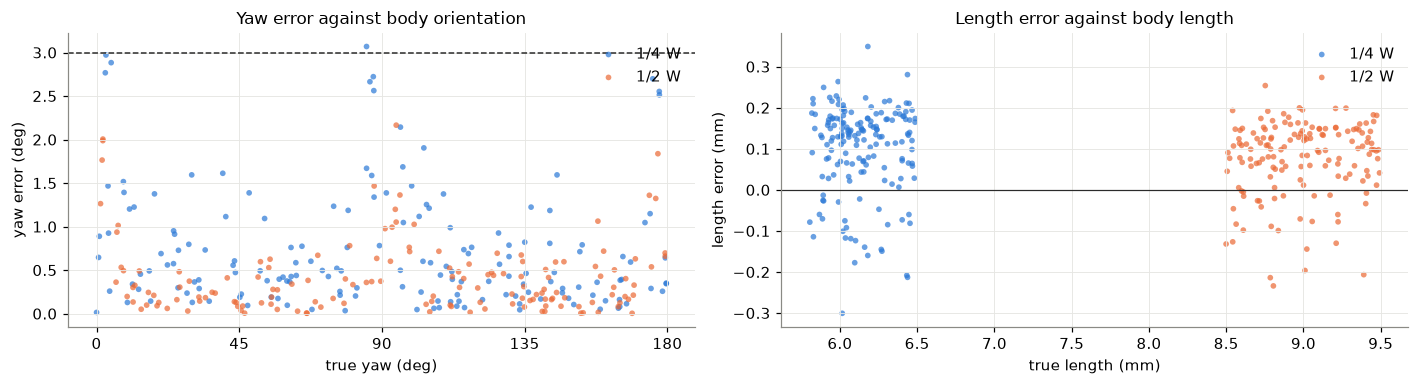

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
for name, colour in [("1/4 W", C1), ("1/2 W", C2)]:
    d = test[test["package"] == name]
    axes[0].scatter(d["true_yaw_deg"], d["yaw_deg"], s=14, color=colour, alpha=0.7,
                    edgecolor="none", label=name)
    axes[1].scatter(d["true_length_mm"], d["length_mm"], s=14, color=colour, alpha=0.7,
                    edgecolor="none", label=name)
axes[0].axhline(evaluate.YAW_TARGET_DEG, color=INK, ls="--", lw=1)
axes[0].set_xlabel("true yaw (deg)"); axes[0].set_ylabel("yaw error (deg)")
axes[0].set_title("Yaw error against body orientation"); axes[0].set_xticks(range(0, 181, 45))
axes[1].axhline(0, color=INK, lw=0.8)
axes[1].set_xlabel("true length (mm)"); axes[1].set_ylabel("length error (mm)")
axes[1].set_title("Length error against body length")
for ax in axes:
    ax.legend(frameon=False)
plt.tight_layout()

### Yaw estimator

The largest yaw errors sit at 0°, 90° and 180°: bodies lined up with the pixel grid. Yaw above
comes from the minimum-area rectangle, whose sides always lie along an edge of the polygon's
convex hull. A predicted outline traced from a raster mask has long straight stair-step edges along
the grid, and the rectangle snaps to them. Yaw from the outline's second moments (the principal
axis of the whole shape) uses every point and does not snap. On the exact label outlines the two
estimators agree to within a tenth of a degree, so the difference below comes from the predicted
outlines alone.

rectangle vs moments yaw on the exact labels: max difference 0.092 deg


,p50,p95,max,bodies > 2 deg
minimum-area rectangle,0.393,1.779,3.069,13.0
second moments,0.275,0.935,2.227,2.0


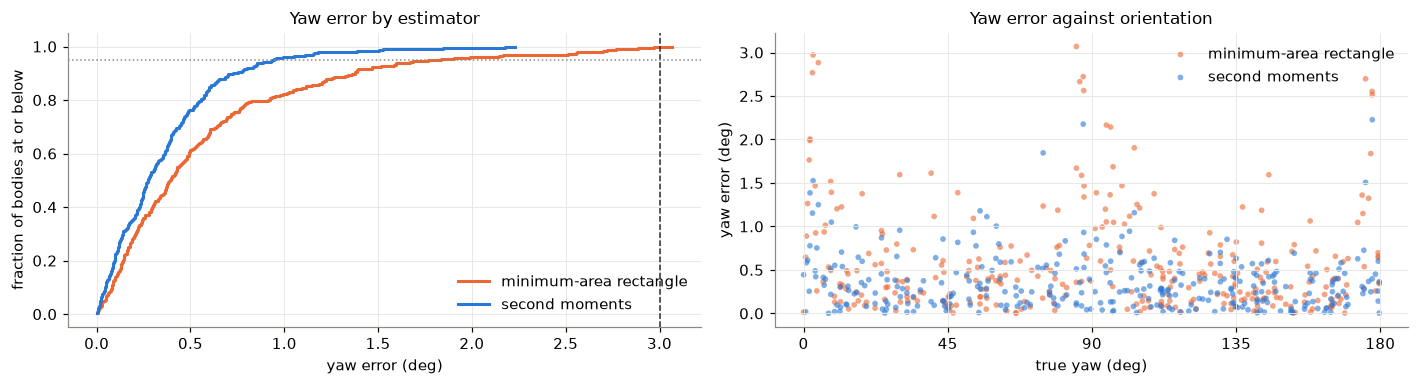

In [11]:
def moment_yaw(points):
    m = cv2.moments(np.asarray(points, np.float32))
    return np.degrees(0.5 * np.arctan2(2 * m["mu11"], m["mu20"] - m["mu02"])) % 180

def angle_diff(a, b):
    d = abs(a - b) % 180
    return min(d, 180 - d)

preds_by_image = {r["image"]: r["polygons"] for r in res["synth_test"]}
test["yaw_moments_deg"] = [
    angle_diff(moment_yaw(manifest.polygons(samples_by_image[row.image])[row.label_index]),
               moment_yaw(preds_by_image[row.image][row.prediction_index]))
    for row in test.itertuples()]
label_agreement = [angle_diff(evaluate.body_geometry(p)[4], moment_yaw(p))
                   for s in SETS["synth_test"] for p in manifest.polygons(s)]
print(f"rectangle vs moments yaw on the exact labels: max difference {max(label_agreement):.3f} deg")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
ecdf(axes[0], test["yaw_deg"], C2, "minimum-area rectangle")
ecdf(axes[0], test["yaw_moments_deg"], C1, "second moments")
axes[0].axvline(evaluate.YAW_TARGET_DEG, color=INK, ls="--", lw=1)
axes[0].axhline(0.95, color=MUTED, ls=":", lw=1)
axes[0].set_xlabel("yaw error (deg)"); axes[0].set_ylabel("fraction of bodies at or below")
axes[0].set_title("Yaw error by estimator"); axes[0].legend(frameon=False, loc="lower right")
axes[1].scatter(test["true_yaw_deg"], test["yaw_deg"], s=14, color=C2, alpha=0.6,
                edgecolor="none", label="minimum-area rectangle")
axes[1].scatter(test["true_yaw_deg"], test["yaw_moments_deg"], s=14, color=C1, alpha=0.6,
                edgecolor="none", label="second moments")
axes[1].set_xticks(range(0, 181, 45)); axes[1].set_xlabel("true yaw (deg)")
axes[1].set_ylabel("yaw error (deg)"); axes[1].set_title("Yaw error against orientation")
axes[1].legend(frameon=False)
plt.tight_layout()
pd.DataFrame({name: {"p50": test[col].median(), "p95": test[col].quantile(0.95),
                     "max": test[col].max(), "bodies > 2 deg": int((test[col] > 2).sum())}
              for name, col in [("minimum-area rectangle", "yaw_deg"),
                                ("second moments", "yaw_moments_deg")]}).T

### Tile seams

A body in the overlap between tiles is predicted by two or more tiles, and the merge must keep
exactly one copy. Bodies are grouped by how many tiles contain them whole.

In [12]:
def tiles_containing(polygon):
    x0, y0 = polygon.min(axis=0); x1, y1 = polygon.max(axis=0)
    return sum(t.x0 <= x0 and t.y0 <= y0 and x1 < t.x0 + t.size and y1 < t.y0 + t.size
               for t in TILES)

test["whole_in_tiles"] = [tiles_containing(manifest.polygons(samples_by_image[row.image])[row.label_index])
                          for row in test.itertuples()]
all_test = res["synth_test"]
print("splits:", sum(r["splits"] for r in all_test), " merges:", sum(r["merges"] for r in all_test),
      " duplicates (false detections):", sum(r["false_detections"] for r in all_test))
test.groupby("whole_in_tiles")[["iou", "centre_mm", "yaw_deg"]].agg(["count", "mean", "max"])

splits: 0  merges: 0  duplicates (false detections): 0


iou               centre_mm               yaw_deg         \
               count   mean    max     count   mean    max   count   mean   
whole_in_tiles                                                              
1                248  0.946  0.973       248  0.052  0.164     248  0.578   
2                 65  0.949  0.969        65  0.044  0.092      65  0.590   
4                  4  0.949  0.958         4  0.039  0.055       4  0.458   

                       
                  max  
whole_in_tiles         
1               3.069  
2               2.884  
4               0.735

### Confidence

All predictions down to 0.05 were kept, so the threshold can be swept without re-running the model.
A second pass over the test frames at 0.001 shows the confidence of everything that is *not* a
body, which at 0.05 is nothing.

recall            precision           false_detections          
set  synth_test synth_val synth_test synth_val       synth_test synth_val
conf                                                                     
0.05      1.000     1.000        1.0       1.0              0.0       0.0
0.10      1.000     1.000        1.0       1.0              0.0       0.0
0.20      1.000     1.000        1.0       1.0              0.0       0.0
0.25      1.000     1.000        1.0       1.0              0.0       0.0
0.30      1.000     1.000        1.0       1.0              0.0       0.0
0.40      1.000     1.000        1.0       1.0              0.0       0.0
0.50      1.000     1.000        1.0       1.0              0.0       0.0
0.60      1.000     1.000        1.0       1.0              0.0       0.0
0.70      1.000     1.000        1.0       1.0              0.0       0.0
0.80      0.991     0.994        1.0       1.0              0.0       0.0
0.90      0.675     0.741        1.0       1.0              0.0       0.0

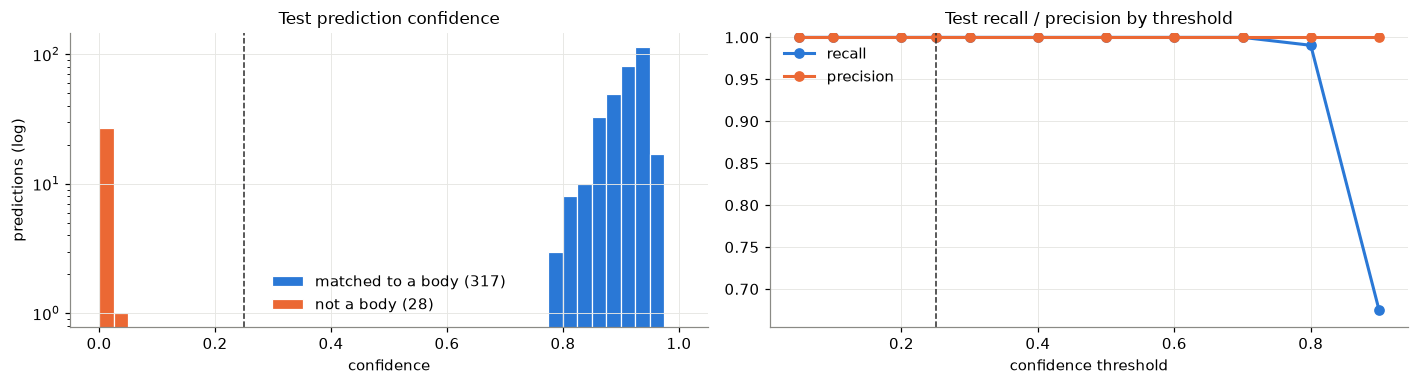

In [13]:
rows = []
for conf in [0.05, 0.1, 0.2, 0.25, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    for name in SETS:
        s = evaluate.summarise(at_conf(raw[name], SETS[name], conf))
        rows.append({"set": name, "conf": conf, **{k: s[k] for k in
                     ["recall", "precision", "misses", "false_detections", "on_target_fraction"]}})
sweep = pd.DataFrame(rows)

LOW_FLOOR = 0.001
low = evaluate.evaluate_samples(model, SETS["synth_test"], conf=LOW_FLOOR)
matched_scores = test["score"].to_numpy()
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
axes[0].hist(matched_scores, bins=np.linspace(0, 1, 41), color=C1, edgecolor="white",
             linewidth=0.8, label=f"matched to a body ({len(matched_scores)})")
other = [r["scores"][i] for r in low for i in range(len(r["scores"]))
         if i not in {m["prediction_index"] for m in r["matched"]}]
axes[0].hist(other, bins=np.linspace(0, 1, 41), color=C2, edgecolor="white", linewidth=0.8,
             label=f"not a body ({len(other)})")
axes[0].axvline(CONF, color=INK, ls="--", lw=1)
axes[0].set_yscale("log"); axes[0].set_xlabel("confidence"); axes[0].set_ylabel("predictions (log)")
axes[0].set_title("Test prediction confidence"); axes[0].legend(frameon=False)
d = sweep[sweep["set"] == "synth_test"]
axes[1].plot(d["conf"], d["recall"], color=C1, marker="o", label="recall")
axes[1].plot(d["conf"], d["precision"], color=C2, marker="o", label="precision")
axes[1].axvline(CONF, color=INK, ls="--", lw=1)
axes[1].set_ylim(min(0.9, d[["recall", "precision"]].min().min() - 0.02), 1.005)
axes[1].set_xlabel("confidence threshold"); axes[1].set_title("Test recall / precision by threshold")
axes[1].legend(frameon=False)
plt.tight_layout()
sweep.pivot(index="conf", columns="set", values=["recall", "precision", "false_detections"])

### Speed

In [14]:
secs = pd.Series([r["seconds"] for name in SETS for r in raw[name]])
print(f"per full frame (8 tiles, includes mask-to-polygon and merge): median {secs.median():.2f} s, "
      f"p95 {secs.quantile(0.95):.2f} s, max {secs.max():.2f} s  (plan: < 1 s on the laptop)")

per full frame (8 tiles, includes mask-to-polygon and merge): median 0.43 s, p95 0.47 s, max 0.70 s  (plan: < 1 s on the laptop)


## 4. Qualitative

### A full test frame

The busiest test frame, cropped to the work area. Tile edges are drawn as thin grey lines.

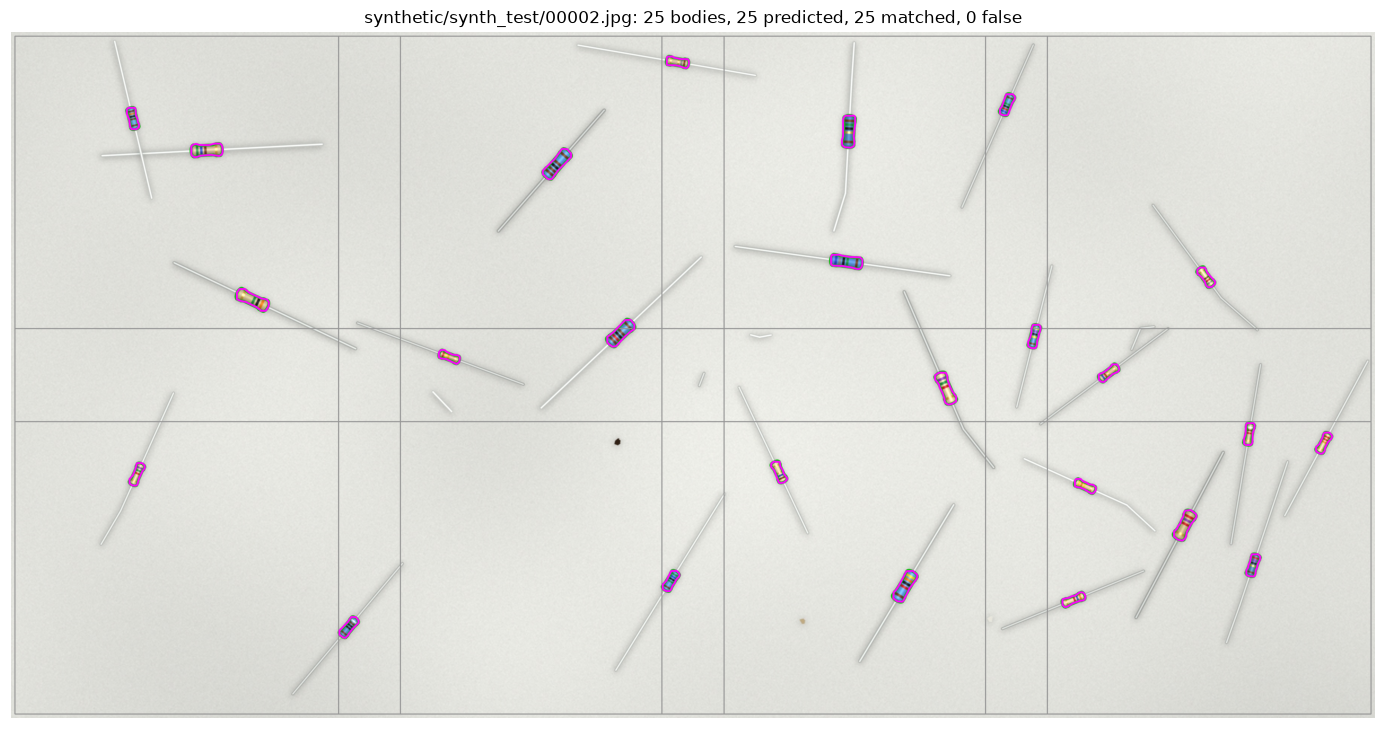

In [15]:
def draw(img, polys, colour, thickness=1, shift=4):
    if polys:
        pts = [np.round(np.asarray(p) * (1 << shift)).astype(np.int32) for p in polys]
        cv2.polylines(img, pts, True, colour, thickness, cv2.LINE_AA, shift=shift)

def full_frame(name, idx, title):
    s, r = SETS[name][idx], res[name][idx]
    img = image(s).copy()
    for t in TILES:
        cv2.rectangle(img, (t.x0, t.y0), (t.x0 + t.size - 1, t.y0 + t.size - 1), (150, 150, 150), 2)
    draw(img, manifest.polygons(s), GT_BGR, 5)
    draw(img, r["polygons"], PRED_BGR, 3)
    x0, y0, w, h = WORK_AREA
    img = img[y0 - 10:y0 + h + 10, x0 - 10:x0 + w + 10]
    plt.figure(figsize=(16, 8.2))
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); plt.axis("off")
    plt.title(f"{title}: {r['labels']} bodies, {r['predictions']} predicted, "
              f"{len(r['matched'])} matched, {r['false_detections']} false")

busiest = int(np.argmax([r["labels"] for r in res["synth_test"]]))
full_frame("synth_test", busiest, SETS["synth_test"][busiest]["image"])

In [16]:
def crop(sample, centre, gt=None, pred=None, half=55, scale=5, extra=()):
    # A zoomed crop with sub-pixel outlines. Pixel (c, r) sits at the centre of its zoomed block.
    img = image(sample)
    c = np.round(centre).astype(int)
    x0, y0 = c - half
    out = cv2.resize(img[y0:y0 + 2 * half, x0:x0 + 2 * half], None, fx=scale, fy=scale,
                     interpolation=cv2.INTER_NEAREST)
    to_crop = lambda p: (np.asarray(p) - (x0, y0)) * scale + (scale - 1) / 2
    for polys, colour in [*extra, ([gt] if gt is not None else [], GT_BGR),
                          ([pred] if pred is not None else [], PRED_BGR)]:
        draw(out, [to_crop(p) for p in polys], colour, 1)
    return cv2.cvtColor(out, cv2.COLOR_BGR2RGB)

def gallery(rows, title, cols=8, half=55, scale=5):
    n = len(rows)
    r_ = int(np.ceil(n / cols))
    fig, axes = plt.subplots(r_, cols, figsize=(2.3 * cols, 2.55 * r_), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, row in zip(axes.flat, rows):
        s = samples_by_image[row.image]
        gt = manifest.polygons(s)[row.label_index]
        pred = res["synth_test"][SETS["synth_test"].index(s)]["polygons"][row.prediction_index]
        ax.imshow(crop(s, gt.mean(axis=0), gt, pred, half, scale))
        ax.set_title(f"IoU {row.iou:.3f}\n{row.centre_mm:.2f} mm, {row.yaw_deg:.1f}°", fontsize=8)
    fig.suptitle(title, y=1.0)
    plt.tight_layout()

### Random bodies

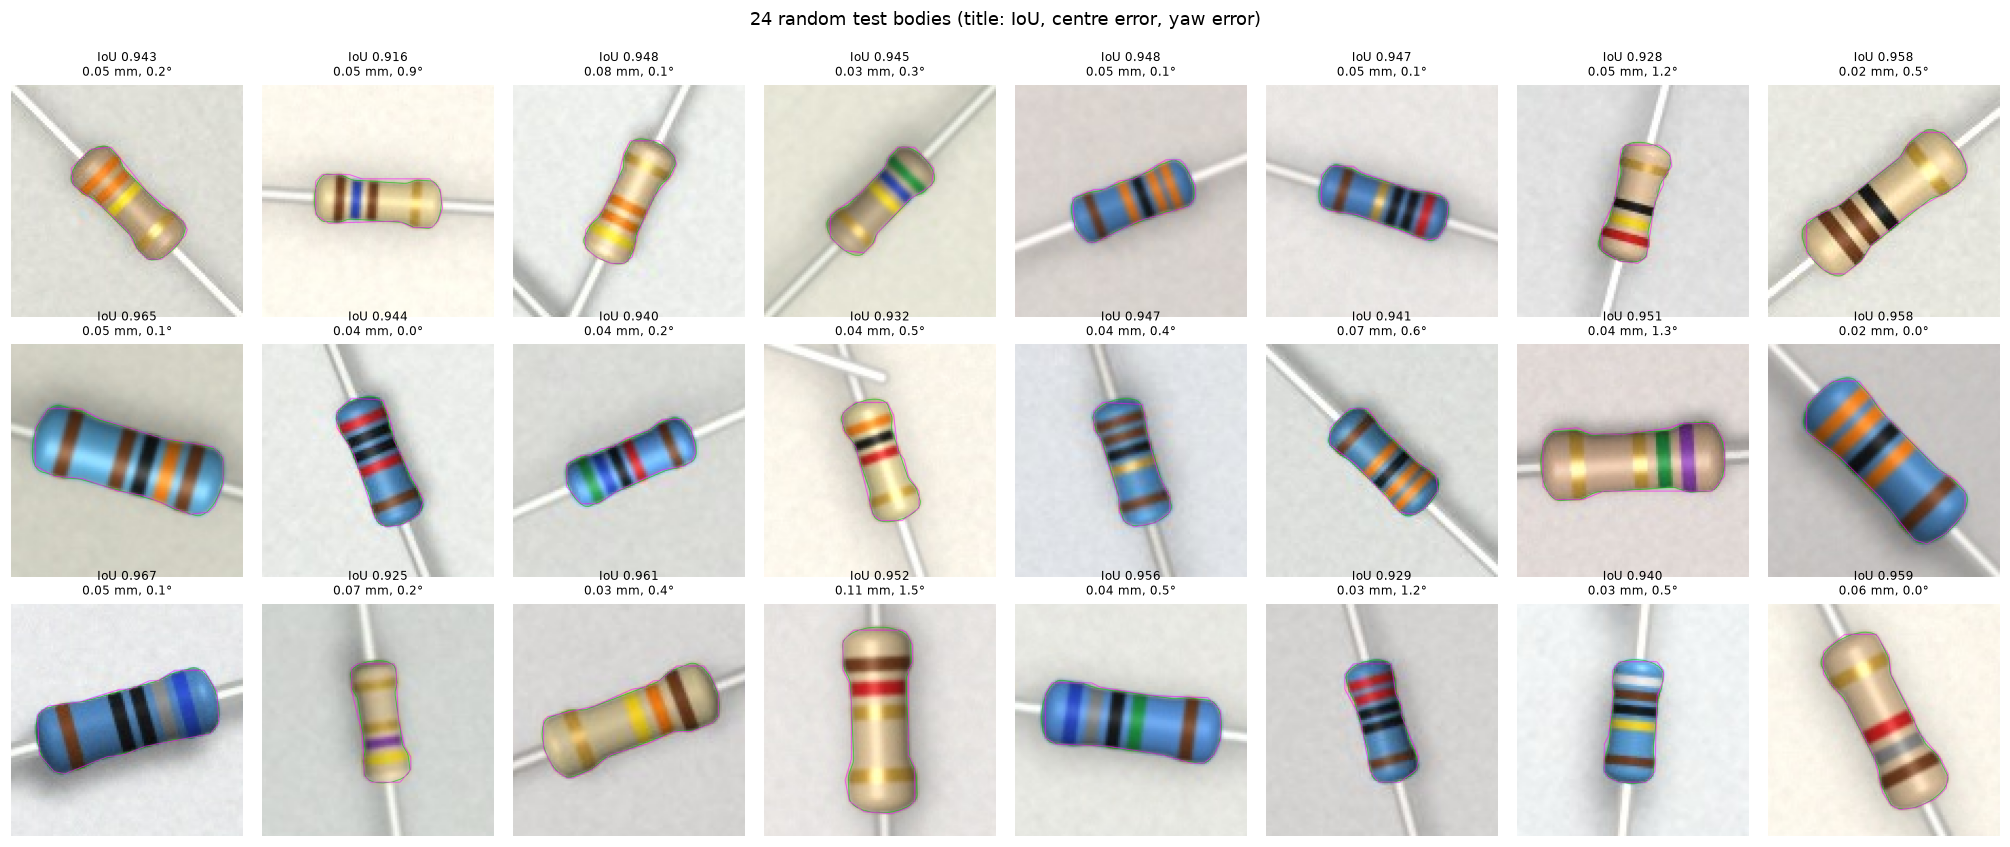

In [17]:
gallery(list(test.sample(24, random_state=0).itertuples()),
        "24 random test bodies (title: IoU, centre error, yaw error)")

### Worst bodies by each measure

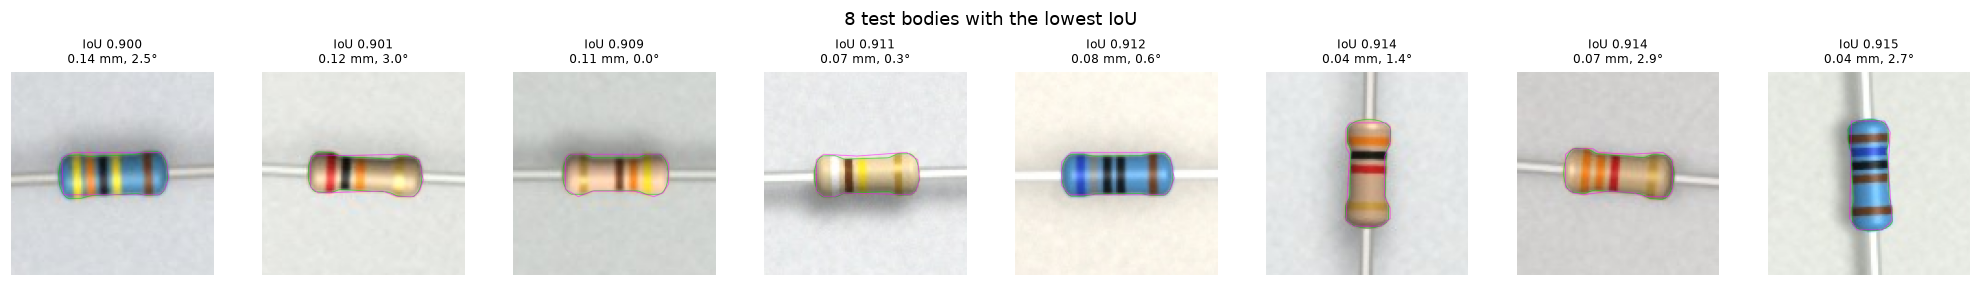

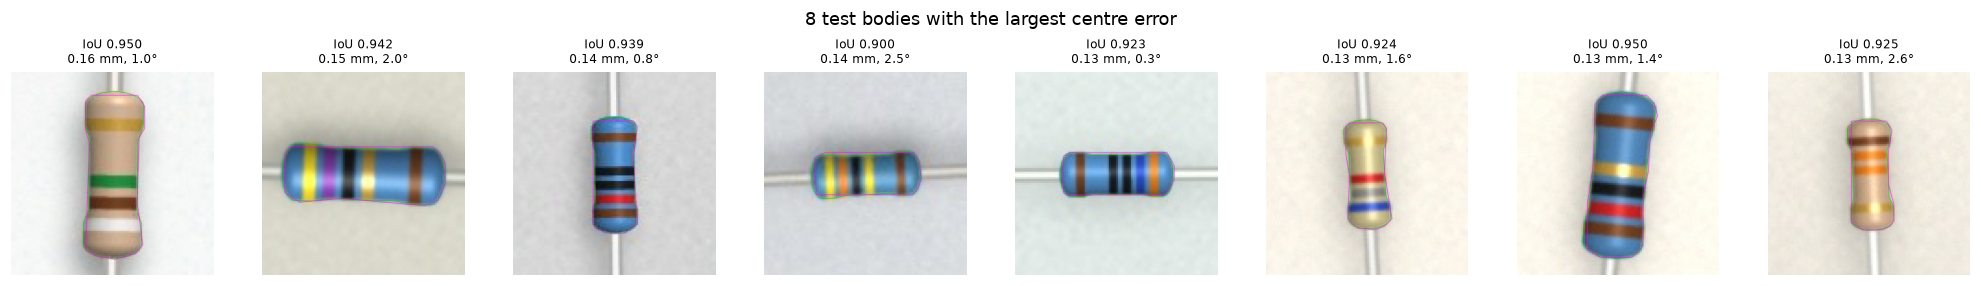

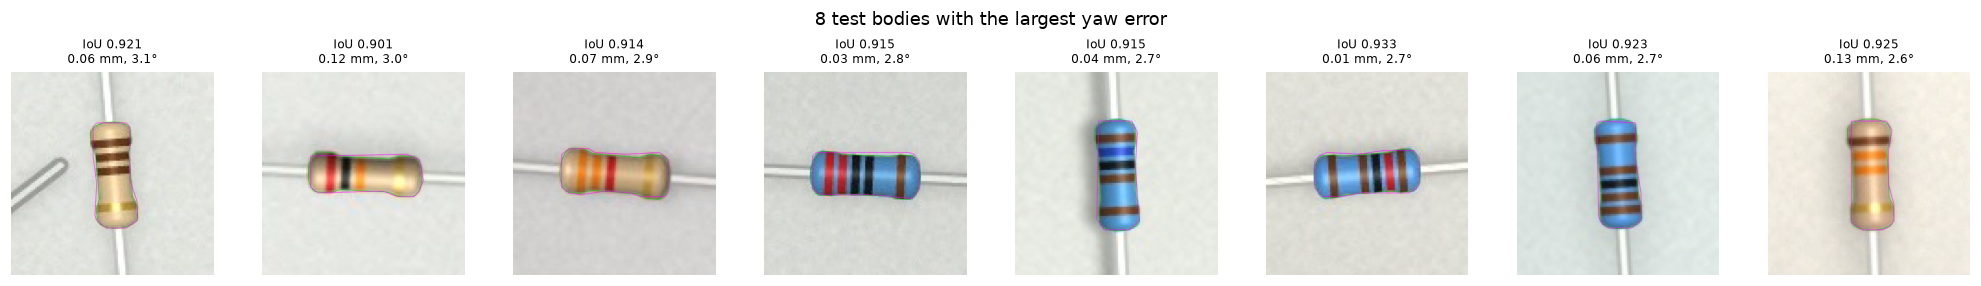

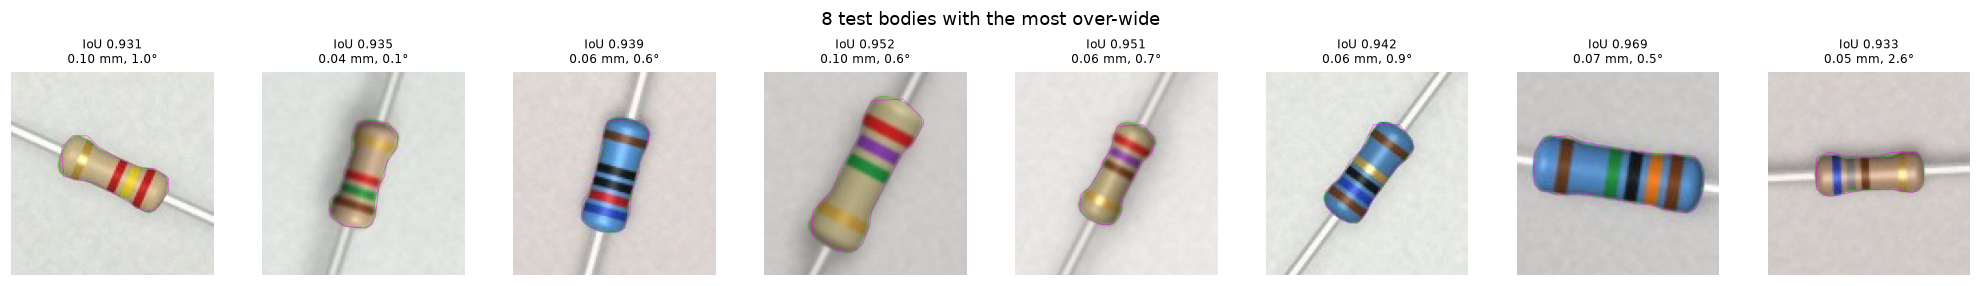

In [18]:
for col, label in [("iou", "lowest IoU"), ("centre_mm", "largest centre error"),
                   ("yaw_deg", "largest yaw error"), ("width_mm", "most over-wide")]:
    worst = test.sort_values(col, ascending=(col == "iou")).head(8)
    gallery(list(worst.itertuples()), f"8 test bodies with the {label}")

### Outline close-up

One ¼ W and one ½ W body at 10× to show how the predicted outline sits against the labelled one.
The prediction is traced from a mask at 1/4 of the tile resolution, upsampled and thresholded.

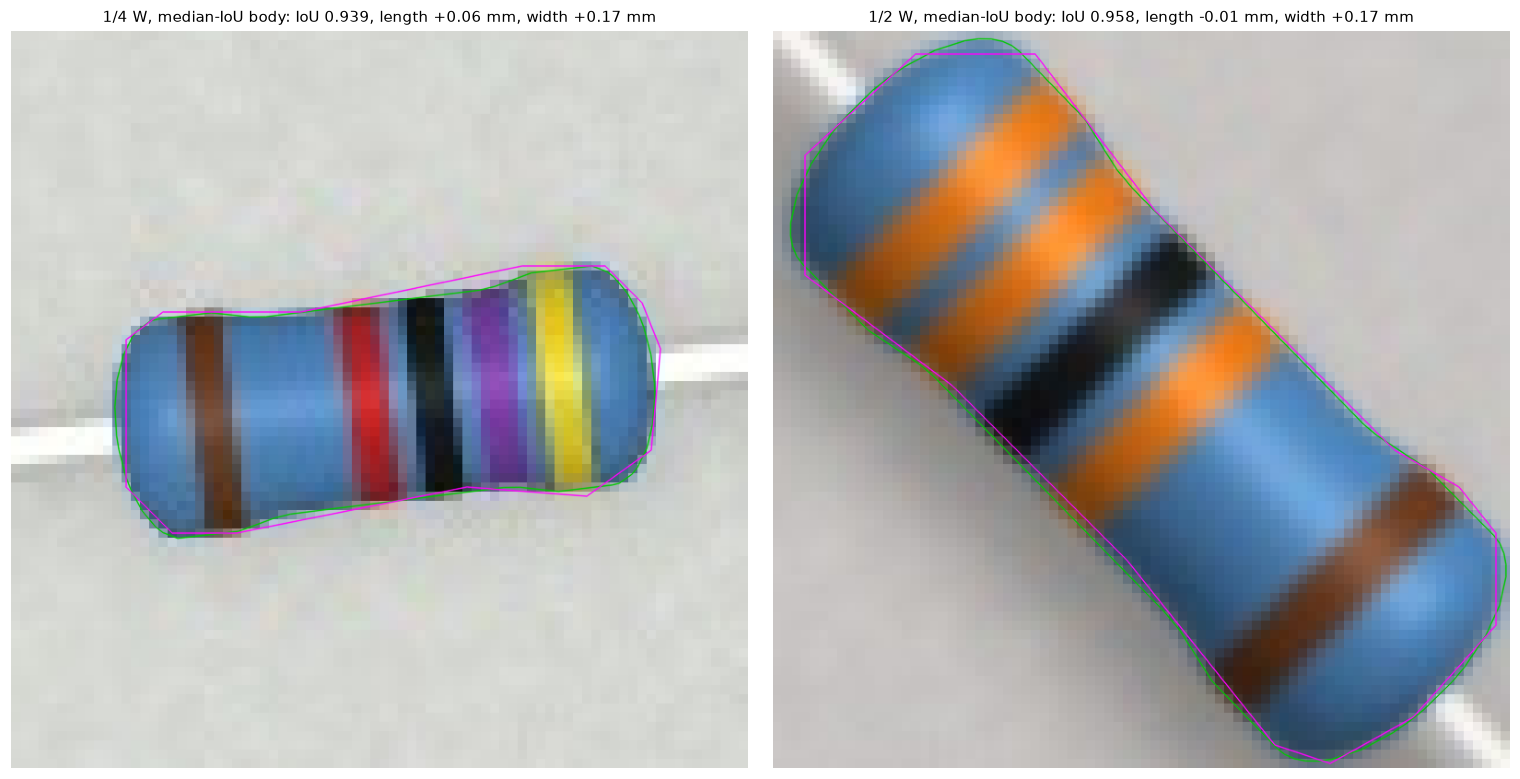

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, pkg in zip(axes, ["1/4 W", "1/2 W"]):
    d = test[test["package"] == pkg]
    row = d.iloc[(d["iou"] - d["iou"].median()).abs().argmin()]
    s = samples_by_image[row["image"]]
    gt = manifest.polygons(s)[int(row["label_index"])]
    pred = res["synth_test"][SETS["synth_test"].index(s)]["polygons"][int(row["prediction_index"])]
    ax.imshow(crop(s, gt.mean(axis=0), gt, pred, half=40, scale=10)); ax.axis("off")
    ax.set_title(f"{pkg}, median-IoU body: IoU {row['iou']:.3f}, length {row['length_mm']:+.2f} mm, "
                 f"width {row['width_mm']:+.2f} mm", fontsize=10)
plt.tight_layout()

### Bodies on tile seams

Test bodies that lie whole in two or more tiles, with the tile edges (grey) that cross the crop.
Each should carry exactly one magenta outline.

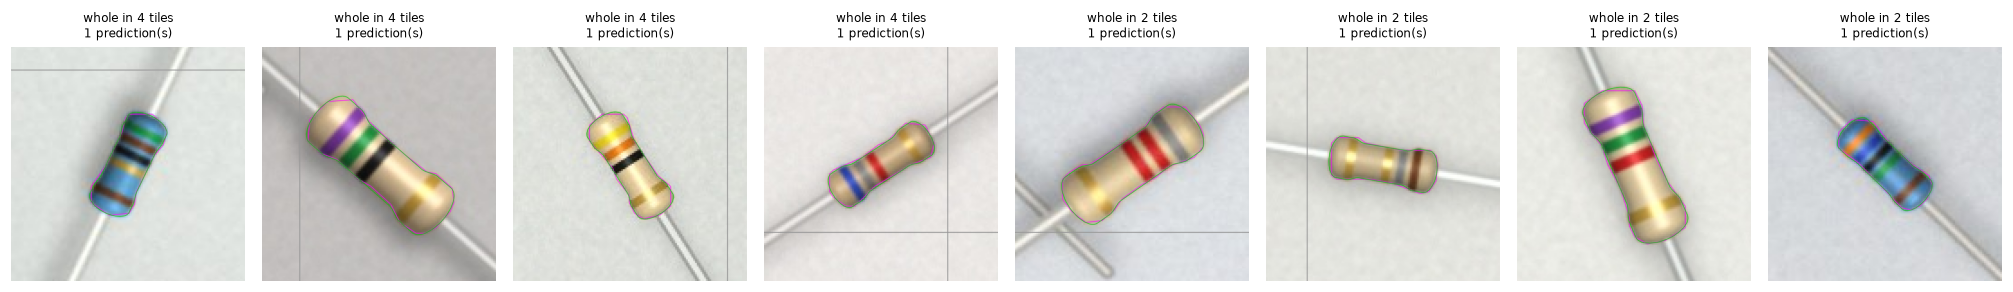

In [20]:
seam = test[test["whole_in_tiles"] >= 2].sort_values("whole_in_tiles", ascending=False).head(8)
fig, axes = plt.subplots(1, len(seam), figsize=(2.3 * max(len(seam), 1), 2.8), squeeze=False)
for ax, row in zip(axes.flat, seam.itertuples()):
    s = samples_by_image[row.image]
    r = res["synth_test"][SETS["synth_test"].index(s)]
    gt = manifest.polygons(s)[row.label_index]
    c = gt.mean(axis=0)
    edges = []
    for t in TILES:
        for x in (t.x0 - 0.5, t.x0 + t.size - 0.5):
            if abs(x - c[0]) < 70:
                edges.append(np.array([[x, c[1] - 80], [x, c[1] + 80]]))
        for y in (t.y0 - 0.5, t.y0 + t.size - 0.5):
            if abs(y - c[1]) < 70:
                edges.append(np.array([[c[0] - 80, y], [c[0] + 80, y]]))
    near = [p for p in r["polygons"] if np.linalg.norm(p.mean(axis=0) - c) < 80]
    img = crop(s, c, gt, None, half=65, scale=4, extra=[(edges, (150, 150, 150)), (near, PRED_BGR)])
    ax.imshow(img); ax.axis("off")
    ax.set_title(f"whole in {row.whole_in_tiles} tiles\n{len(near)} prediction(s)", fontsize=8)
plt.tight_layout()

### What the model nearly detects

The highest-scoring test predictions that match no body, from the pass at 0.001. At the
operating threshold of 0.25 these are all dropped; this shows what the model finds most body-like
in the clutter (lead offcuts, crumbs) and how close it comes to a false detection.

28 unmatched predictions >= 0.001; 0 at or above 0.25


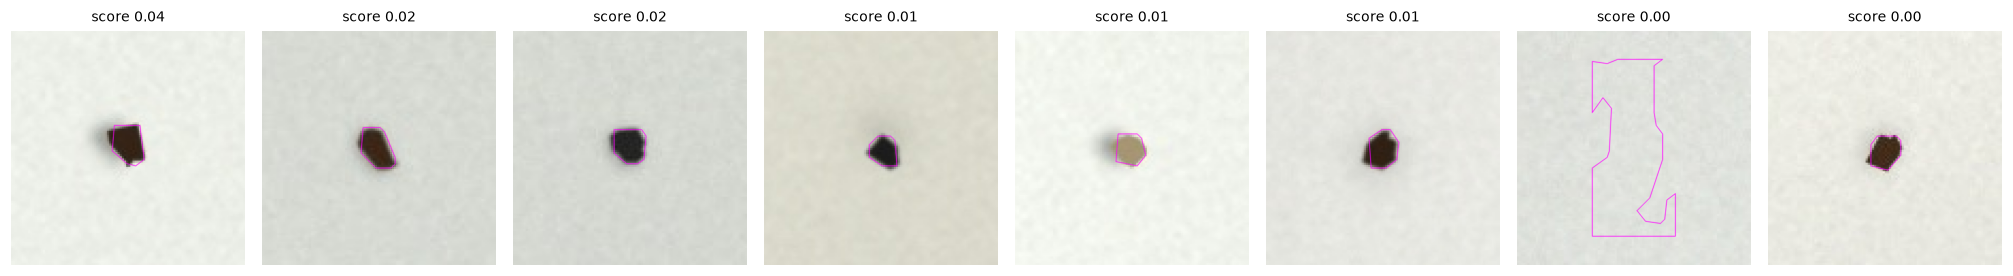

In [21]:
near_misses = []
for r, s in zip(low, SETS["synth_test"]):
    matched = {m["prediction_index"] for m in r["matched"]}
    for i, (p, sc) in enumerate(zip(r["polygons"], r["scores"])):
        if i not in matched:
            near_misses.append((sc, s, p))
near_misses.sort(key=lambda t: -t[0])
print(f"{len(near_misses)} unmatched predictions >= {LOW_FLOOR}; "
      f"{sum(sc >= CONF for sc, _, _ in near_misses)} at or above {CONF}")
show = near_misses[:8]
if show:
    fig, axes = plt.subplots(1, len(show), figsize=(2.3 * len(show), 2.8), squeeze=False)
    for ax, (sc, s, p) in zip(axes.flat, show):
        ax.imshow(crop(s, p.mean(axis=0), None, p, half=55, scale=4)); ax.axis("off")
        ax.set_title(f"score {sc:.2f}", fontsize=9)
    plt.tight_layout()

### Empty frames

Frames with no resistors, only clutter. Any magenta outline here is a false detection.

2 empty frames: [('synth_val', 'synthetic/synth_val/00013.jpg', 0), ('synth_test', 'synthetic/synth_test/00001.jpg', 0)]


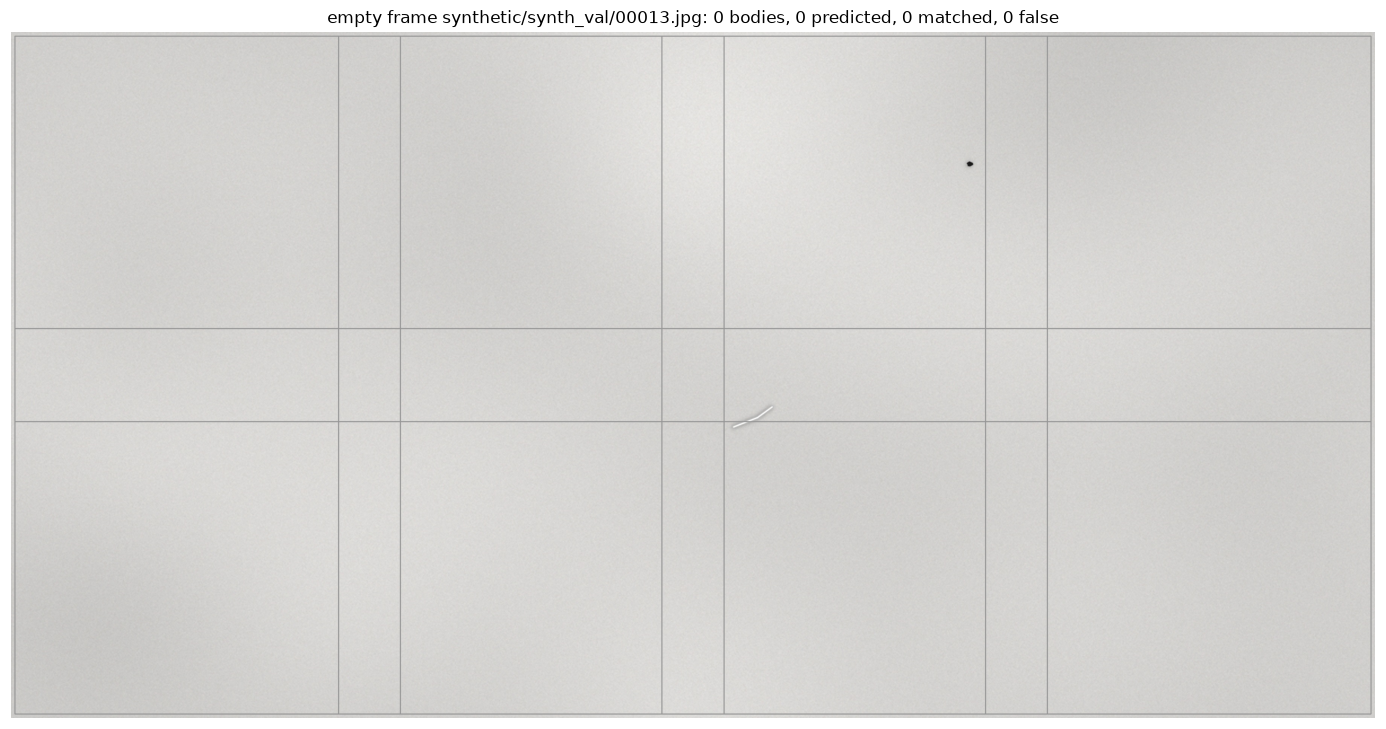

In [22]:
empties = [(name, i) for name in SETS for i, s in enumerate(SETS[name]) if not s["instances"]]
print(f"{len(empties)} empty frames:",
      [(name, SETS[name][i]["image"], res[name][i]["predictions"]) for name, i in empties])
if empties:
    full_frame(*empties[0], title=f"empty frame {SETS[empties[0][0]][empties[0][1]]['image']}")

## 5. Findings

**Detection is perfect on this synthetic test.** 317 of 317 test bodies (and 317 of 317 val)
found, no false detections, none on the empty frames, no merges or splits. Body predictions score
0.78 to 0.97; everything else scores 0.04 or less (all of it table crumbs, never lead offcuts), so any
threshold from 0.05 to 0.7 gives the same result.

**Position is well inside the target.** Centre error p95 is 0.10 mm against the 1 mm target, with no
systematic offset (mean dx +0.01 mm, dy −0.02 mm).

**Yaw meets the target, and most of the remaining error comes from how yaw is measured.** With the
minimum-area rectangle, yaw p95 is 1.78° against 3°, and one body of 317 is over (3.07°), so 99.7 %
of bodies are on target. The large errors cluster where bodies line up with the pixel grid (0°, 90°,
180°), because the rectangle snaps to the stair-step edges of the traced outline. Taking yaw from
the outline's second moments instead halves p95 to 0.94° (max 2.2°), and the two estimators agree on
exact outlines. **Recommendation:** the robot repo should take yaw from moments (or a PCA of the
outline), not `cv2.minAreaRect`. Worth checking how its Detection does it now.

**Outlines run slightly fat.** Width +0.16 mm (about 1.5 px, 6 % of a ¼ W body's width) and length
+0.09 mm on average, the same across all four body types, so it is systematic. The close-ups show
why: the outline is traced from a mask at ¼ of the tile resolution, which rounds the end caps and
cuts across the waist. ¼ W bodies, with fewer pixels, have lower IoU (0.94 against 0.96) and twice
the yaw p95 of ½ W bodies. If width or length feed a decision on the robot (gripper opening,
telling ¼ W from ½ W), the bias is small and consistent enough to subtract; a finer mask
(`mask_ratio`, retina masks during training, or Mask R-CNN as `docs/plan.md` suggests) is the
other route.

**Tiling and merging work.** Bodies whole in two or four tiles are as accurate as the rest and each
gets exactly one prediction.

**Speed fits the budget on this GPU.** 0.43 s median per full frame (8 tiles plus merge) on the RTX
3060 laptop GPU, against the 1 s target. This says nothing yet about a CPU-only or embedded target.

**Training needs watching.** Precision collapsed to 0.13 at epoch 4 (the first full-rate epoch after
warmup) and recovered at epoch 5. `best.pt` avoids it, but a longer run may want a lower `lr0` or a
longer warmup.

**What this does and does not show.** The model, tiling, merge and scoring pipeline work end to end,
and on synthetic data the task is effectively solved in 5 epochs. Because test frames come from the
same generator, these numbers are an upper bound: lighting, real lacquer, glare and MJPG artefacts
are not tested. A longer baseline-against-tuned comparison on synthetic data would mostly move
outline fidelity (the width bias and yaw); detection has no headroom left. Real frames are now the
deciding test.